In [ ]:
import os
import cv2
import numpy as np
from PIL import Image

# Exact folder names from your unzipped archive
BASE_DIR = r"./dataset"
IMAGE_DIR = os.path.join(BASE_DIR, "ISIC2018_Task1-2_Training_Input")
MASK_DIR = os.path.join(BASE_DIR, "ISIC2018_Task1_Training_GroundTruth")

def analyze_isic_dataset(img_dir, mask_dir):
    if not os.path.exists(img_dir) or not os.path.exists(mask_dir):
        print("Error: One or both directories not found. Check your folder names!")
        return

    img_files = sorted([f for f in os.listdir(img_dir) if f.endswith('.jpg')])
    mask_files = sorted([f for f in os.listdir(mask_dir) if f.endswith('.png')])
    
    print(f"--- Dataset Overview ---")
    print(f"Total Source Images (.jpg): {len(img_files)}")
    print(f"Total Ground Truth Masks (.png): {len(mask_files)}\n")
    
    # Analyze a sample distribution of resolutions (checking first 30 images)
    widths, heights, aspect_ratios = [], [], []
    mask_unique_values = set()
    
    sample_size = min(30, len(img_files))
    for i in range(sample_size):
        img_path = os.path.join(img_dir, img_files[i])
        mask_path = os.path.join(mask_dir, mask_files[i])
        
        with Image.open(img_path) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)
            aspect_ratios.append(w / h)
            
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask is not None:
            mask_unique_values.update(np.unique(mask))

    print(f"--- Raw Dimensional Analysis (Sample of {sample_size}) ---")
    print(f"Image Widths:  Min = {min(widths)}px, Max = {max(widths)}px, Mean = {int(np.mean(widths))}px")
    print(f"Image Heights: Min = {min(heights)}px, Max = {max(heights)}px, Mean = {int(np.mean(heights))}px")
    print(f"Aspect Ratios: Min = {min(aspect_ratios):.2f}, Max = {max(aspect_ratios):.2f}")
    print(f"Unique values inside raw Mask pixels: {sorted(list(mask_unique_values))}")

analyze_isic_dataset(IMAGE_DIR, MASK_DIR)

--- Dataset Overview ---
Total Source Images (.jpg): 2594
Total Ground Truth Masks (.png): 2594

--- Raw Dimensional Analysis (Sample of 30) ---
Image Widths:  Min = 1022px, Max = 1504px, Mean = 1279px
Image Heights: Min = 767px, Max = 1129px, Mean = 960px
Aspect Ratios: Min = 1.33, Max = 1.33
Unique values inside raw Mask pixels: [np.uint8(0), np.uint8(255)]


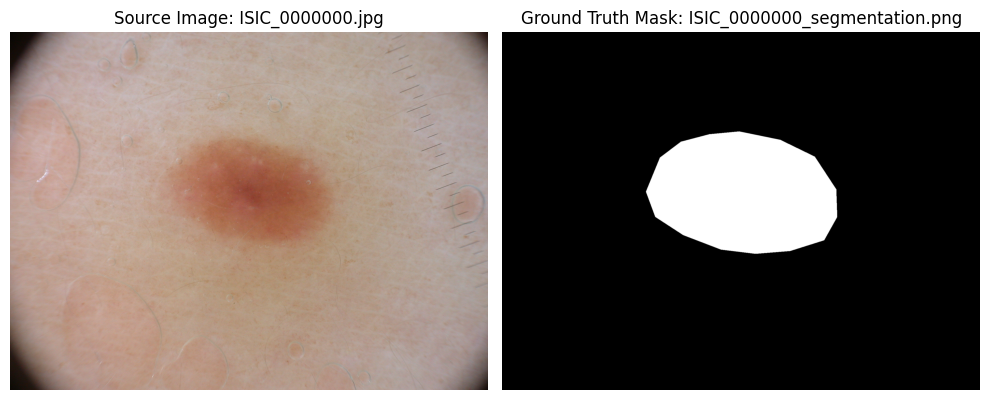

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

# 1. Base path configuration using your exact unzipped folder layout
BASE_PATH = r"./dataset"
IMAGE_DIR = os.path.join(BASE_PATH, "ISIC2018_Task1-2_Training_Input")
MASK_DIR = os.path.join(BASE_PATH, "ISIC2018_Task1_Training_GroundTruth")

# 2. Safely read and sort files
img_files = sorted([f for f in os.listdir(IMAGE_DIR) if f.endswith('.jpg')])
mask_files = sorted([f for f in os.listdir(MASK_DIR) if f.endswith('.png')])

# 3. Pull the first matching sample pair
sample_img_path = os.path.join(IMAGE_DIR, img_files[100])
sample_mask_path = os.path.join(MASK_DIR, mask_files[100])

img_sample = cv2.imread(sample_img_path)
img_sample = cv2.cvtColor(img_sample, cv2.COLOR_BGR2RGB)
mask_sample = cv2.imread(sample_mask_path, cv2.IMREAD_GRAYSCALE)

# 4. Generate the side-by-side plot
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img_sample)
axes[0].set_title(f"Source Image: {img_files[0]}")
axes[0].axis('off')

axes[1].imshow(mask_sample, cmap='gray')
axes[1].set_title(f"Ground Truth Mask: {mask_files[0]}")
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import os
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# 1. Base path configuration mapping exactly to your unzipped folders
BASE_PATH = r"./dataset"
TRAIN_IMG_DIR = os.path.join(BASE_PATH, "ISIC2018_Task1-2_Training_Input")
TRAIN_MASK_DIR = os.path.join(BASE_PATH, "ISIC2018_Task1_Training_GroundTruth")
VAL_IMG_DIR = os.path.join(BASE_PATH, "ISIC2018_Task1-2_Validation_Input")

IMG_SIZE = (256, 256)

def get_paired_paths(img_dir, mask_dir=None):
    img_files = sorted([f for f in os.listdir(img_dir) if f.endswith('.jpg')])
    pairs = []
    
    if mask_dir:
        mask_files = sorted([f for f in os.listdir(mask_dir) if f.endswith('.png')])
        for img_f in img_files:
            # Match ISIC_0000000.jpg with ISIC_0000000_segmentation.png
            base_id = img_f.split('.')[0]
            expected_mask = f"{base_id}_segmentation.png"
            if expected_mask in mask_files:
                pairs.append((os.path.join(img_dir, img_f), os.path.join(mask_dir, expected_mask)))
    else:
        # For folders that don't have masks (like raw test inputs)
        for img_f in img_files:
            pairs.append((os.path.join(img_dir, img_f), None))
            
    return pairs

# Gather our official dataset splits
train_pairs = get_paired_paths(TRAIN_IMG_DIR, TRAIN_MASK_DIR)
print(f"--- Split Summary ---")
print(f"Official Training Set Pairs: {len(train_pairs)}")

# 2. Custom PyTorch Dataset Class
class ISICDataset(Dataset):
    def __init__(self, file_pairs, img_size=(256, 256)):
        self.file_pairs = file_pairs
        self.img_size = img_size

    def __len__(self):
        return len(self.file_pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.file_pairs[idx]

        # Load and process color source image
        img = Image.open(img_path).convert('RGB')
        img = img.resize(self.img_size)
        img_np = np.array(img, dtype=np.float32) / 255.0  # Normalize to [0,1]
        img_tensor = torch.from_numpy(img_np).permute(2, 0, 1)  # (Channels, H, W)

        if mask_path:
            # Load and process grayscale ground truth mask
            mask = Image.open(mask_path).convert('L')
            mask = mask.resize(self.img_size, resample=Image.NEAREST)  # Keep boundaries crisp
            mask_np = np.array(mask, dtype=np.float32) / 255.0  # Convert to exactly 0.0 or 1.0
            mask_tensor = torch.from_numpy(mask_np).unsqueeze(0)  # (1, H, W)
        else:
            mask_tensor = torch.empty(0)

        return img_tensor, mask_tensor

# 3. Create the active data stream loaders
train_dataset = ISICDataset(train_pairs, img_size=IMG_SIZE)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

# Run a quick check to see if a batch passes smoothly
sample_imgs, sample_masks = next(iter(train_loader))
print(f"\nPyTorch DataLoader Sanity Check:")
print(f"Images batch tensor shape: {sample_imgs.shape}  --> (Batch, Channels, H, W)")
print(f"Masks batch tensor shape:  {sample_masks.shape}  --> (Batch, Channels, H, W)")


--- Split Summary ---
Official Training Set Pairs: 2594

PyTorch DataLoader Sanity Check:
Images batch tensor shape: torch.Size([16, 3, 256, 256])  --> (Batch, Channels, H, W)
Masks batch tensor shape:  torch.Size([16, 1, 256, 256])  --> (Batch, Channels, H, W)
